In [1]:
import pandas as pd
import networkx as nx
from google.colab import files
import matplotlib.pyplot as plt

print("Faça o upload do arquivo da rede (ex: 'DNA Repair'):")
uploaded_rede = files.upload()
filename_rede = next(iter(uploaded_rede))

# Constrói o grafo G
G = nx.read_edgelist(filename_rede)
print(f"Rede carregada com sucesso! Nós: {G.number_of_nodes()} | Arestas: {G.number_of_edges()}")

Faça o upload do arquivo da rede (ex: 'DNA Repair'):


Saving DNA Repair to DNA Repair
Rede carregada com sucesso! Nós: 332 | Arestas: 8353


In [2]:
print("Faça o upload do arquivo 'canonical_drivers.txt':")
uploaded_drivers = files.upload()
filename_drivers = next(iter(uploaded_drivers))

# Lê os drivers e transforma em conjunto
df_genes = pd.read_csv(filename_drivers, header=None)
drivers_totais = set(df_genes[0])

# Interseção com os nós da rede e definição dos não-drivers
driversSet = drivers_totais & set(G.nodes())
nonDrivers = set(G.nodes()) - driversSet

print(f"Ambiente pronto! Drivers na rede: {len(driversSet)} | Não-drivers: {len(nonDrivers)}")

Faça o upload do arquivo 'canonical_drivers.txt':


Saving canonical_drivers.txt to canonical_drivers.txt
Ambiente pronto! Drivers na rede: 43 | Não-drivers: 289


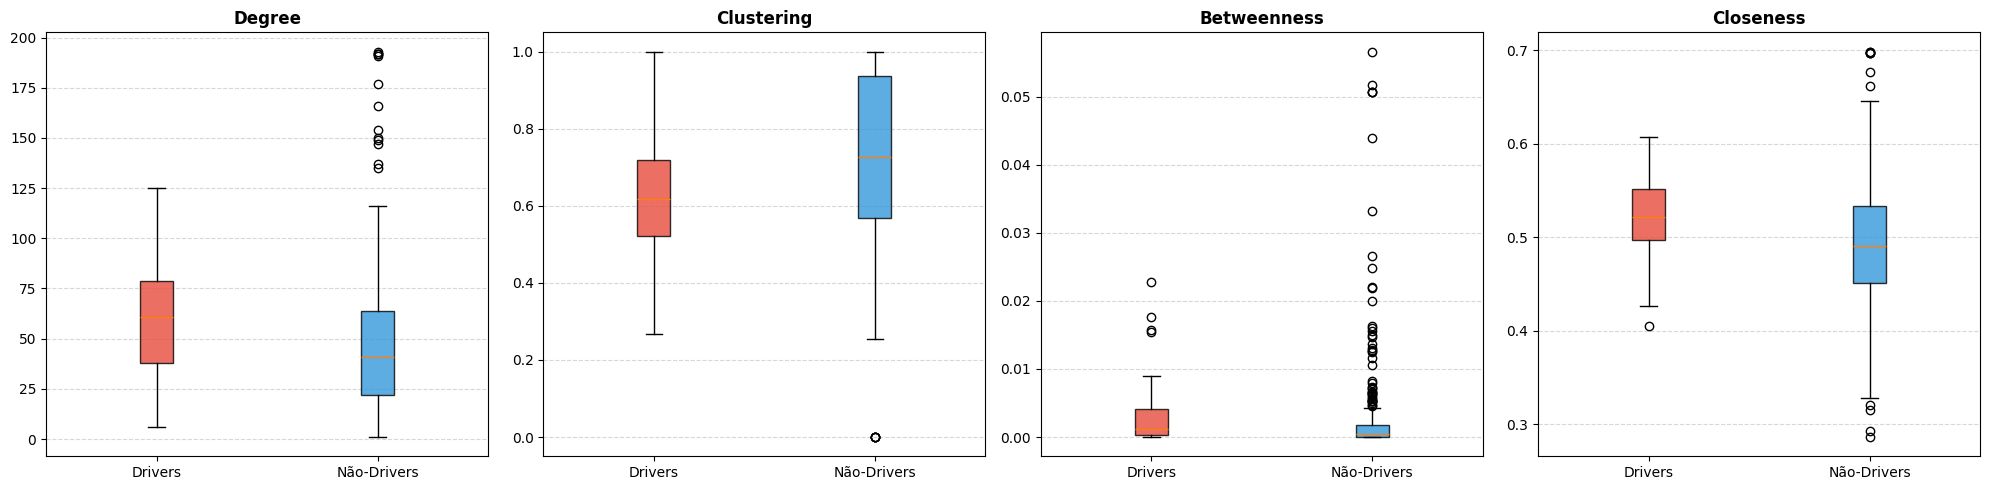

In [3]:
import matplotlib.pyplot as plt
import networkx as nx

# 1. Calcula as quatro métricas de centralidade exigidas
degree_dict = dict(G.degree())
clustering_dict = nx.clustering(G)
betweenness_dict = nx.betweenness_centrality(G)
closeness_dict = nx.closeness_centrality(G)

metricas = {
    'Degree': degree_dict,
    'Clustering': clustering_dict,
    'Betweenness': betweenness_dict,
    'Closeness': closeness_dict
}

# 2. Configura a figura com 4 subgráficos (um para cada métrica)
fig, axes = plt.subplots(1, 4, figsize=(20, 5), dpi=100)

for idx, (nome_metrica, valores_metrica) in enumerate(metricas.items()):
    # Separa os valores correspondentes aos drivers e aos não-drivers
    valores_drivers = [valores_metrica[node] for node in driversSet]
    valores_nondrivers = [valores_metrica[node] for node in nonDrivers]

    # Plota o boxplot
    bplot = axes[idx].boxplot(
        [valores_drivers, valores_nondrivers],
        tick_labels=['Drivers', 'Não-Drivers'],
        patch_artist=True
    )

    # Colore as caixas (Vermelho para drivers, Azul para não-drivers)
    cores = ['#e74c3c', '#3498db']
    for patch, cor in zip(bplot['boxes'], cores):
        patch.set_facecolor(cor)
        patch.set_alpha(0.8)

    axes[idx].set_title(nome_metrica, fontweight='bold')
    axes[idx].grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

=== Top 3 Genes Drivers Mais Impactantes ===
1º Lugar: TP53 (Impacto: -0.000030)
2º Lugar: BRCA1 (Impacto: -0.000025)
3º Lugar: ATM (Impacto: -0.000021)


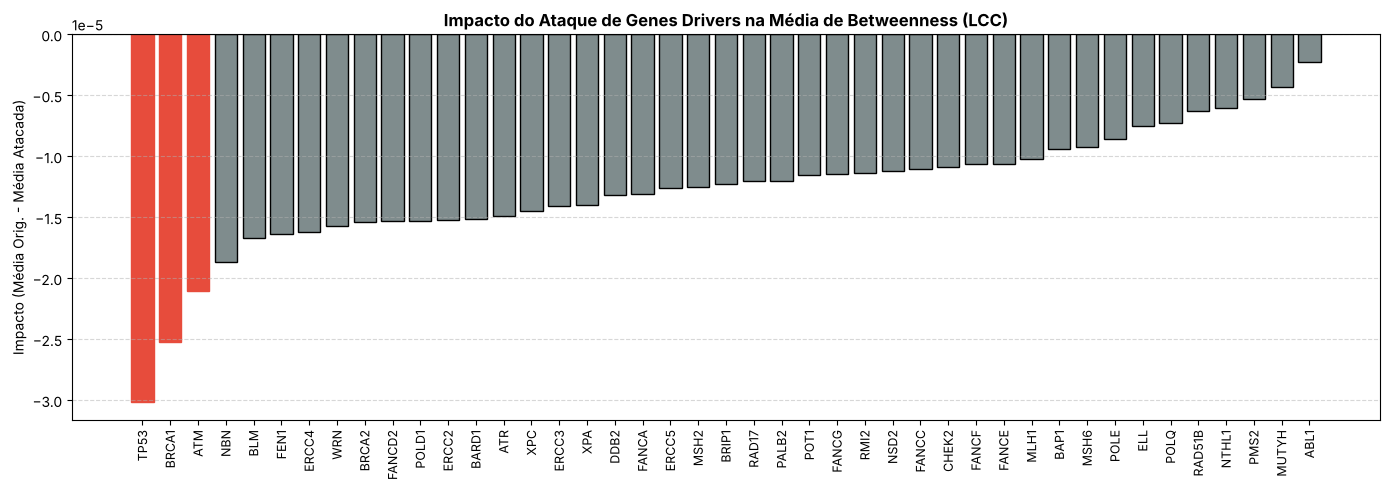

In [ ]:
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt

# 1. Isola o Maior Componente Conexo (LCC) da rede original e calcula a média base
maior_comp_orig = max(nx.connected_components(G), key=len)
G_lcc_orig = G.subgraph(maior_comp_orig)

betw_orig = nx.betweenness_centrality(G_lcc_orig)
media_base = np.mean(list(betw_orig.values()))

impactos = {}

# 2. Simula o ataque individual para cada gene driver
for driver in driversSet:
    G_ataque = G.copy()
    G_ataque.remove_node(driver)

    # Extrai o novo Maior Componente Conexo após a remoção do nó
    componentes = list(nx.connected_components(G_ataque))
    if not componentes:
        continue

    maior_comp_ataque = max(componentes, key=len)
    G_lcc_ataque = G_ataque.subgraph(maior_comp_ataque)

    # Recalcula a métrica de Betweenness e extrai a nova média
    betw_ataque = nx.betweenness_centrality(G_lcc_ataque)
    media_ataque = np.mean(list(betw_ataque.values()))

    # Armazena o impacto (Média Original - Média Atacada)
    impactos[driver] = media_base - media_ataque

# 3. Ordena pelo MÓDULO do impacto (todos os impactos são negativos: quanto mais negativo, maior o impacto)
impactos_ordenados = sorted(impactos.items(), key=lambda x: abs(x[1]), reverse=True)

print("=== Top 3 Genes Drivers Mais Impactantes ===")
for i in range(3):
    gene, impacto = impactos_ordenados[i]
    print(f"{i+1}º Lugar: {gene} (Impacto: {impacto:.6f})")

# 4. Plota o gráfico de barras com o resultado de todos os ataques
genes = [item[0] for item in impactos_ordenados]
valores = [item[1] for item in impactos_ordenados]

plt.figure(figsize=(14, 5), dpi=100)
barras = plt.bar(genes, valores, color='#7f8c8d', edgecolor='black')

# Destaca as barras dos 3 genes mais impactantes em vermelho
for i in range(min(3, len(barras))):
    barras[i].set_color('#e74c3c')

plt.title('Impacto do Ataque de Genes Drivers na Média de Betweenness (LCC)', fontweight='bold')
plt.ylabel('Impacto (Média Orig. - Média Atacada)')
plt.axhline(0, color='black', lw=0.8)
plt.xticks(rotation=90, fontsize=9)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()